---

MRI analysis 

---

In [1]:
# autoload
%load_ext autoreload
%autoreload 2
from pgl import pgl, pglDatabase, pglActions, pglFlywheel, pglAFNI, pglActionsMRI, pglActionsMNE, pglActionsFixes


---

Load behavioral data

---

In [ ]:
pgl.importSettings()

In [ ]:
newSession = pglActions.loadSession.execute()
if newSession: 
    session = newSession
    session.print()

---

Fix missing volume triggers

---

In [ ]:
fixVolumeTimes = pglActionsFixes.fixVolumeTimes()
newSession = fixVolumeTimes.execute(session=session)
if newSession: 
    session = newSession
    session.print()

In [ ]:
session.display()

In [ ]:
session.print()

---

Load data from flywheel

---

In [ ]:
newSession = pglActions.loadFlywheel().execute(session=session, showScanCounts=False)
if newSession: 
    session = newSession
    session.print()

In [ ]:
session.mri.print(match='nsdmini')

In [ ]:
session.saveRawSession()

---

AFNI: check availability and optional install

---

In [ ]:
afni = pglAFNI(directory="~/proj/afni/abin")
available = afni.checkAvailable("3dvolreg")

In [ ]:
afni = pglAFNI()
afni.install()

In [ ]:
pglActionsMRI.help()


In [2]:
from pgl import pglDatabase
#pglDatabase.print()
session = pglDatabase.loadSession(126)

(pglDatabase:_reconstructSessionBundle) Restored 1 scan/run matches by acquisition identity; no matching action was replayed.
=================================== Session ====================================
  Source checkpoint : 126
  Runs              : 10
  Filesystem        : pglcheckpoint
  MEG/EEG data      : None
  MRI data          : 48 scans

---------------------------- Experiment and subject ----------------------------
  nsd-mini / sdbp_nsdmini_0002

------------------------------------ Run 1 -------------------------------------
Experiment: nsd-mini | Subject ID: sdbp_nsdmini_0002
Session: session_2026-11-13 | Run: run_12-28-39
2026-11-13T12:32:11.679832-08:00
Duration: 6 mins 16s
Number of volume triggers: 240
Median time between triggers: 1.510s
Mean ± std time between triggers: 1.569 ± 0.870336s
Suspected manual final trigger: trigger 240, gap=14.835s; excluded from missing-volume and timing-discrepancy counts.
Duration and interval statistics above still include this fi

In [5]:
session.print()

=================================== Session ====================================
  Source checkpoint : 126
  Runs              : 10
  Filesystem        : pglcheckpoint
  MEG/EEG data      : None
  MRI data          : 48 scans

---------------------------- Experiment and subject ----------------------------
  nsd-mini / sdbp_nsdmini_0002

------------------------------------ Run 1 -------------------------------------
Experiment: nsd-mini | Subject ID: sdbp_nsdmini_0002
Session: session_2026-11-13 | Run: run_12-28-39
2026-11-13T12:32:11.679832-08:00
Duration: 6 mins 16s
Number of volume triggers: 240
Median time between triggers: 1.510s
Mean ± std time between triggers: 1.569 ± 0.870336s
Suspected manual final trigger: trigger 240, gap=14.835s; excluded from missing-volume and timing-discrepancy counts.
Duration and interval statistics above still include this final trigger.
Possible missing volumes = 2
No interval timing discrepancies ≥100 ms detected, excluding any suspected manual fi

In [ ]:
session.setScanRunMatches([(4, 0), (5, 1), (6, 2), (10, 3), (11, 4), (12, 5), (17,6), (21, 7), (22, 8), (23, 9)])
#session.setScanRunMatches([(4, 0)])

(pglSession:printScanRunMatches) Scan/run correspondence: 1 matched pairs; indices are zero-based.
(pglSession:printScanRunMatches)   MRI scan 4 (nsdmini_run01_bold_1p4mm_R3x3_esp570_TR1510:
1_3_12_2_1107_5_2_61_251202_2026111312313389043002453_0_0_0.nii.gz) ↔ behavioral run 0
(pglSession:printScanRunMatches)   Unmatched MRI scans: 0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26,
27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47
(pglSession:printScanRunMatches)   Unmatched behavioral runs: 1, 2, 3, 4, 5, 6, 7, 8, 9
(pglSession:printScanRunMatches)   These are acquisition matches only; volume correspondence and clock alignment are separate.
(pglSession:setScanRunMatches) Correspondence updated in memory. Use saveSession() to preserve matches with the session's MRI, behavioral contents, and
derived products.


[(4, 0)]

Timeline alignment: first. Behavioral timestamps remain unchanged.
  Each matched MRI scan is shifted independently; inter-scan spacing may change.
  Volume correspondence is ordinal: first ↔ first, second ↔ second, etc.
  Scan 4 ↔ Run 0: 241 pairs; MRI shift=-3.186185 s.
    Align MRI first volume 1794601934.000000 UTC s → behavioral first trigger 1794601930.813815 UTC s.
    After alignment: RMS=0.000 ms; max absolute difference=0.000 ms.
  Run 0: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 1: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 2: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 3: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 4: segment ticks from main task 0 ('nSD-mini'

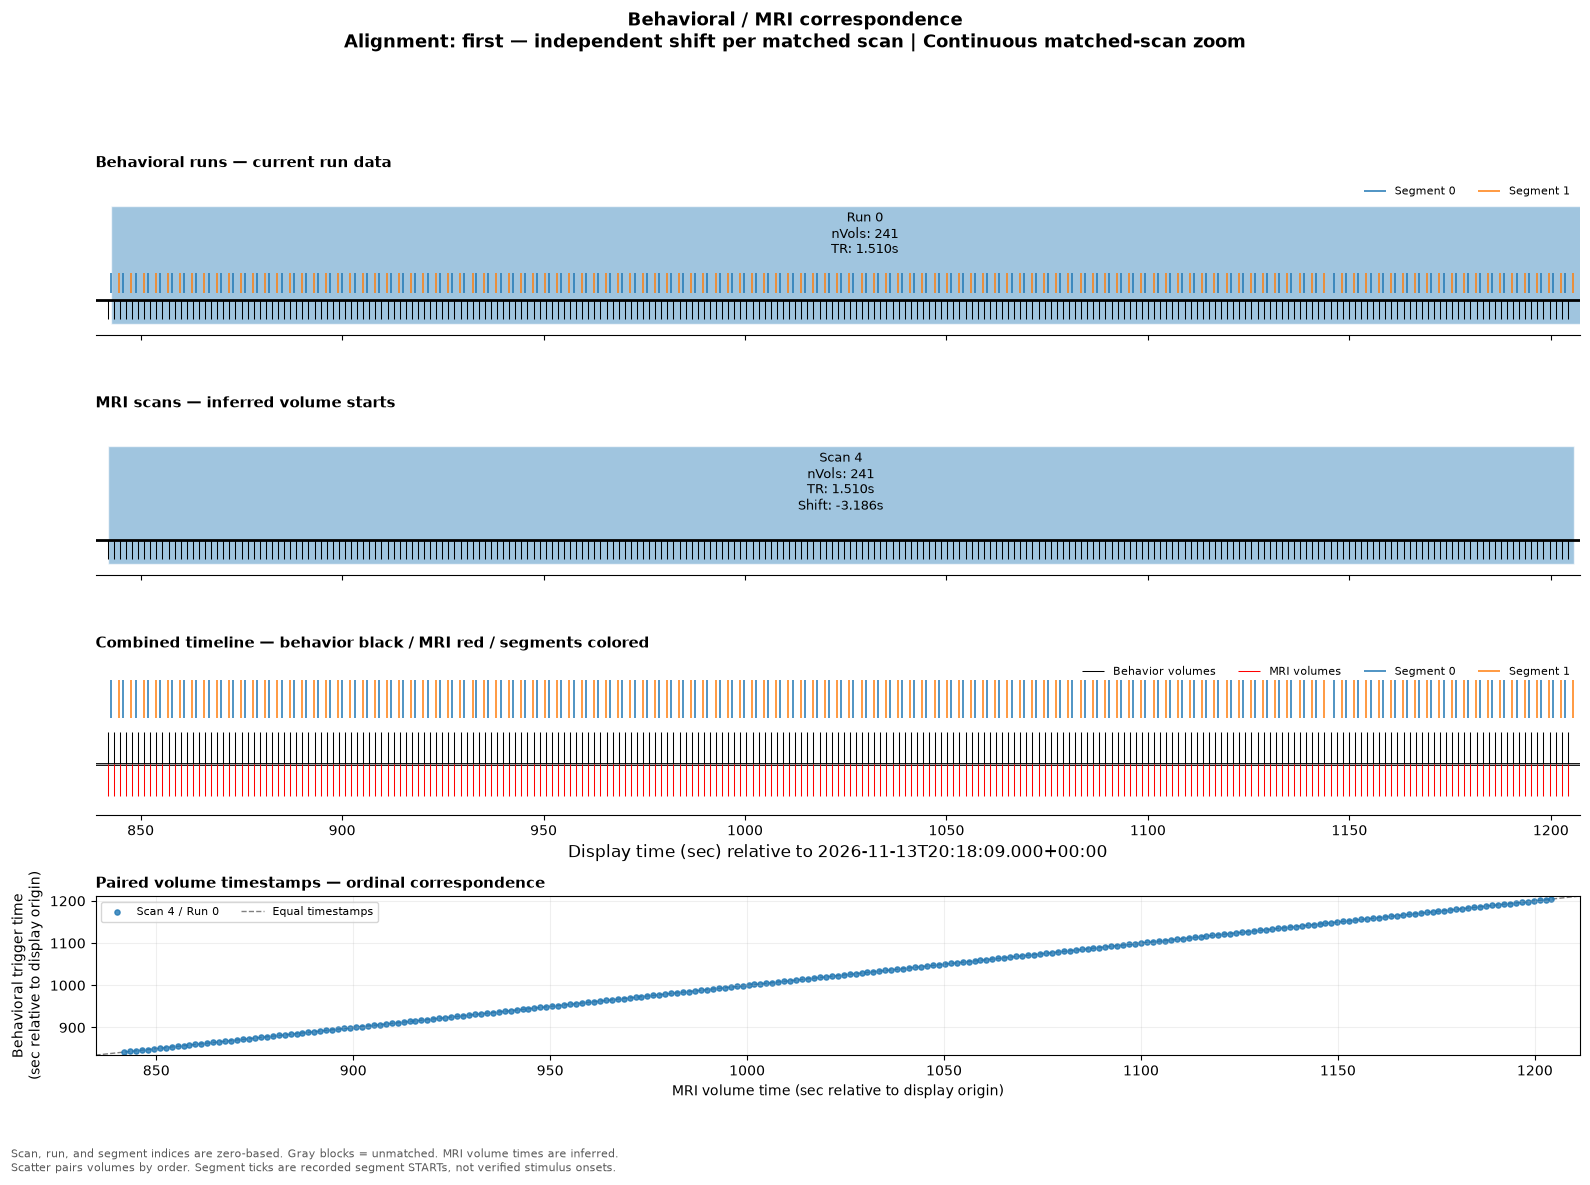

In [9]:
session.displayScanRunMapping()

---

Run motion comp

---

In [ ]:
newSession = pglActionsMRI.mriEstimateMotionAFNI().execute(session=session, deferApply=True)
if newSession: session = newSession

In [ ]:
session.saveSession()

In [ ]:
session.mri.print()

In [5]:
newSession = pglActionsFixes.reconstructVolumeTriggersFromNifti.execute(session=session)
if newSession: session = newSession

(reconstructVolumeTriggersFromNifti:_afterSuccess) Run 0 ↔ MRI scan 4: 240 → 241 volume triggers; TR=1.50999999s; first timestamp=537703.390024792 retained.


In [13]:
newSession.print()

=================================== Session ====================================
  Source checkpoint : 126
  Runs              : 10
  Filesystem        : pglcheckpoint
  MEG/EEG data      : None
  MRI data          : 48 scans

---------------------------- Experiment and subject ----------------------------
  nsd-mini / sdbp_nsdmini_0002

------------------------------------ Run 1 -------------------------------------
Experiment: nsd-mini | Subject ID: sdbp_nsdmini_0002
Session: session_2026-11-13 | Run: run_12-28-39
2026-11-13T12:32:11.679832-08:00
Duration: 6 mins 3s
Number of volume triggers: 241
Median time between triggers: 1.510s
Mean ± std time between triggers: 1.510 ± 0.000000s
No interval timing discrepancies ≥100 ms detected, excluding any suspected manual final trigger.
taskName: NSD-mini (nTrials=120)

------------------------------------ Run 2 -------------------------------------
Experiment: nsd-mini | Subject ID: sdbp_nsdmini_0002
Session: session_2026-11-13 | Run: run_1